# Modelos de Cox con covariables dependientes del tiempo
**UNMSM · E.P. de Estadística · Modelos de supervivencia**

Cohorte de 600 pacientes (artritis reumatoide / espondiloartritis axial) en formato start-stop.
Ejecuta las celdas en orden **desde la carpeta `trabajox/`** (donde está la carpeta `datos/`).

## 0. Configuración, carga y validación

In [1]:
import json, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from types import SimpleNamespace
from lifelines import KaplanMeierFitter, CoxTimeVaryingFitter
from lifelines.statistics import multivariate_logrank_test
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.nonparametric.smoothers_lowess import lowess

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold"})

BASE = Path.cwd()
TAB, FIG = BASE / "salida" / "tablas", BASE / "salida" / "figuras"
WEB_DATA, WEB_IMG = BASE / "web" / "data", BASE / "web" / "imagenes"
for c in (TAB, FIG, WEB_DATA, WEB_IMG):
    c.mkdir(parents=True, exist_ok=True)

ORDEN = ["Convencional", "Biologico_A", "Biologico_B"]
ETQ_T = {"Convencional": "Convencional (MTX)", "Biologico_A": "Biológico A (anti-TNF)",
         "Biologico_B": "Biológico B (anti-IL-6/IL-17)"}
COL = {"Convencional": "#64748B", "Biologico_A": "#2563EB", "Biologico_B": "#F97316"}
COV = ["trat_A", "trat_B", "edad10", "pcr", "pas10", "adh"]
ETQ = {"trat_A": "Biológico A vs Convencional", "trat_B": "Biológico B vs Convencional",
       "edad10": "Edad (por 10 años)", "pcr": "PCR (por 1 mg/L)", "pas10": "PAS (por 10 mmHg)",
       "adh": "Adherencia alta vs baja", "A_lt": "Biológico A × log(t)", "B_lt": "Biológico B × log(t)"}
Z = stats.norm.ppf(0.975)


def guardar_fig(nombre):
    plt.savefig(FIG / nombre, dpi=200, bbox_inches="tight")
    plt.show()


def guardar_tab(df, nombre):
    df.to_csv(TAB / nombre, index=False, encoding="utf-8-sig")


def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"


# --- Carga ---
archivo = sorted((BASE / "datos").glob("*.xlsx"))[0]
df = pd.read_excel(archivo)
df.columns = [c.strip().lower() for c in df.columns]
df["tratamiento"] = pd.Categorical(df["tratamiento"].str.strip(), categories=ORDEN, ordered=True)
df["adh"] = (df["adherencia"].str.strip() == "Alta").astype(int)       # Alta = 1, Baja = 0 (ref)
df["trat_A"] = (df["tratamiento"] == "Biologico_A").astype(int)         # ref = Convencional
df["trat_B"] = (df["tratamiento"] == "Biologico_B").astype(int)
df["edad10"], df["pas10"] = df["edad"] / 10, df["pas"] / 10             # coeficientes por 10 años / 10 mmHg
df = df.sort_values(["id", "t_start"]).reset_index(drop=True)

# --- Validación del formato start-stop ---
g = df.groupby("id", observed=True)
sig = g["t_start"].shift(-1)
ultima = g.cumcount(ascending=False) == 0
val = pd.DataFrame([
    ("Filas / pacientes", f"{len(df)} / {df['id'].nunique()}"),
    ("Valores faltantes", int(df.isna().sum().sum())),
    ("t_start >= t_stop", int((df["t_start"] >= df["t_stop"]).sum())),
    ("Pacientes que no inician en 0", int((g["t_start"].first() != 0).sum())),
    ("Huecos/solapamientos entre intervalos", int((((sig - df["t_stop"]).abs() > 1e-9) & sig.notna()).sum())),
    ("Eventos fuera de la última fila", int(((df["evento"] == 1) & ~ultima).sum())),
    ("Tratamiento o edad cambiantes", int(((g["tratamiento"].nunique() > 1) | (g["edad"].nunique() > 1)).sum())),
], columns=["Chequeo", "Resultado"])
guardar_tab(val, "00_validacion.csv")
val

,Chequeo,Resultado
0,Filas / pacientes,7636 / 600
1,Valores faltantes,0
2,t_start >= t_stop,0
3,Pacientes que no inician en 0,0
4,Huecos/solapamientos entre intervalos,0
5,Eventos fuera de la última fila,0
6,Tratamiento o edad cambiantes,0


## 1. Análisis descriptivo

In [2]:
pac = g.agg(tratamiento=("tratamiento", "first"), edad=("edad", "first"), tiempo=("t_stop", "max"),
            evento=("evento", "max"), n_visitas=("t_stop", "size"), pcr0=("pcr", "first"),
            pas0=("pas", "first"), adh0=("adh", "first")).reset_index()
pac["tratamiento"] = pd.Categorical(pac["tratamiento"], categories=ORDEN, ordered=True)


def resumen(p, d):
    k, pm = int(p["evento"].sum()), (d["t_stop"] - d["t_start"]).sum()
    lo = stats.chi2.ppf(.025, 2 * k) / 2 / pm
    hi = stats.chi2.ppf(.975, 2 * (k + 1)) / 2 / pm
    q = lambda x: f"{x.median():.1f} ({x.quantile(.25):.1f}–{x.quantile(.75):.1f})"
    return {"Pacientes": len(p), "Eventos, n (%)": f"{k} ({100 * k / len(p):.1f}%)",
            "Persona-meses": f"{pm:,.0f}",
            "Tasa por 100 persona-meses (IC 95%)": f"{100 * k / pm:.2f} ({100 * lo:.2f}–{100 * hi:.2f})",
            "Tiempo en estudio, mediana (RIC)": q(p["tiempo"]),
            "Edad, media (DE)": f"{p['edad'].mean():.1f} ({p['edad'].std():.1f})",
            "PCR basal, mediana (RIC)": q(p["pcr0"]),
            "PAS basal, media (DE)": f"{p['pas0'].mean():.1f} ({p['pas0'].std():.1f})",
            "Adherencia alta, % de intervalos": f"{100 * d['adh'].mean():.1f}"}


tabla1 = pd.DataFrame({ETQ_T[t]: resumen(pac[pac.tratamiento == t], df[df.tratamiento == t]) for t in ORDEN}
                      | {"Total": resumen(pac, df)})
tabla1.index.name = "Característica"
guardar_tab(tabla1.reset_index(), "01_descriptiva.csv")
print(f"PCR: asimetría = {df['pcr'].skew():.2f} (muy sesgada a la derecha)")
tabla1

PCR: asimetría = 1.83 (muy sesgada a la derecha)


,Convencional (MTX),Biológico A (anti-TNF),Biológico B (anti-IL-6/IL-17),Total
Característica,,,,
Pacientes,195,197,208,600
"Eventos, n (%)",77 (39.5%),109 (55.3%),68 (32.7%),254 (42.3%)
Persona-meses,"7,281","7,533","7,434","22,248"
Tasa por 100 persona-meses (IC 95%),1.06 (0.83–1.32),1.45 (1.19–1.75),0.91 (0.71–1.16),1.14 (1.01–1.29)
"Tiempo en estudio, mediana (RIC)",42.1 (15.4–60.0),40.9 (25.8–53.2),38.2 (14.1–60.0),40.7 (16.8–60.0)
"Edad, media (DE)",58.0 (10.3),59.2 (10.7),58.9 (11.0),58.7 (10.7)
"PCR basal, mediana (RIC)",6.0 (4.4–7.8),6.5 (4.5–8.7),5.8 (4.4–8.6),6.0 (4.4–8.4)
"PAS basal, media (DE)",130.6 (15.5),128.3 (14.6),130.6 (14.6),129.9 (14.9)
"Adherencia alta, % de intervalos",72.5,73.0,69.7,71.7


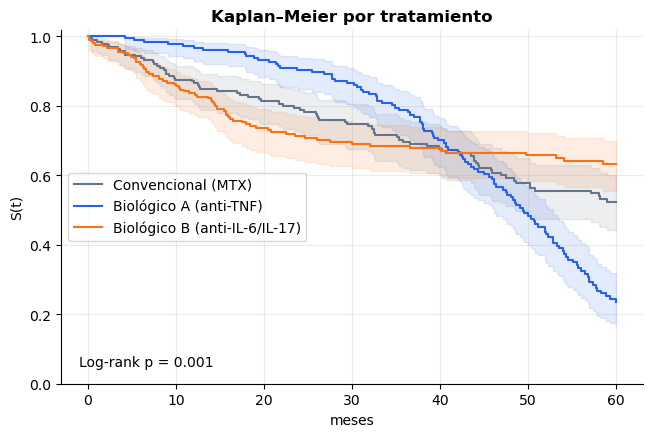

Log-rank: chi2 = 13.22, gl = 2, p = 0.001


In [4]:
# Kaplan–Meier por tratamiento (el tratamiento es fijo, así que KM es válido)
lr = multivariate_logrank_test(pac["tiempo"], pac["tratamiento"].astype(str), pac["evento"])
grid = np.arange(0, 61.0)
km_web = {}
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for t in ORDEN:
    s = pac[pac.tratamiento == t]
    kmf = KaplanMeierFitter().fit(s["tiempo"], s["evento"], label=ETQ_T[t])
    kmf.plot_survival_function(ax=ax, ci_alpha=.12, color=COL[t])
    sf = kmf.survival_function_.reindex(grid, method="ffill").iloc[:, 0]
    km_web[t] = {"t": grid.tolist(), "S": sf.tolist()}
ax.set(title="Kaplan–Meier por tratamiento", xlabel="meses", ylabel="S(t)", ylim=(0, 1.02))
ax.text(.03, .05, f"Log-rank p = {fmt_p(lr.p_value)}", transform=ax.transAxes)
guardar_fig("fig01_km.png")
print(f"Log-rank: chi2 = {lr.test_statistic:.2f}, gl = 2, p = {fmt_p(lr.p_value)}")

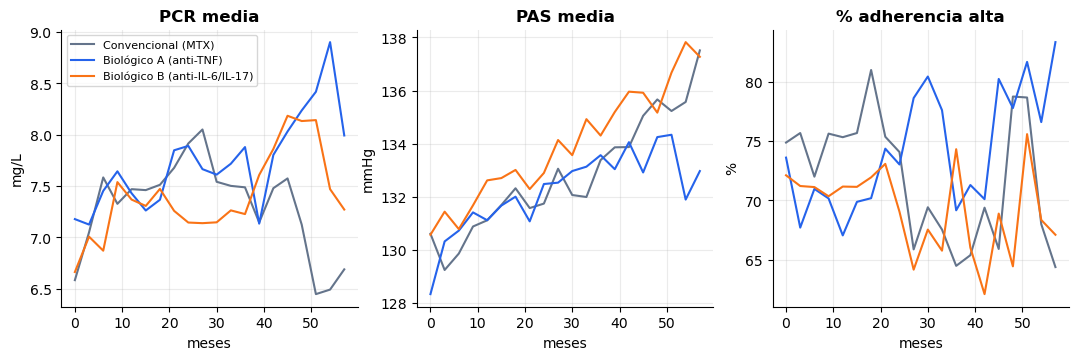

In [5]:
# Trayectorias medias de las covariables dependientes del tiempo
tr = (df.groupby(["tratamiento", "t_start"], observed=True)
        .agg(pcr=("pcr", "mean"), pas=("pas", "mean"), adh=("adh", "mean"), n=("id", "size")).reset_index())
tr = tr[tr["n"] >= 20]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for t in ORDEN:
    s = tr[tr.tratamiento == t]
    ax[0].plot(s.t_start, s.pcr, color=COL[t], label=ETQ_T[t])
    ax[1].plot(s.t_start, s.pas, color=COL[t])
    ax[2].plot(s.t_start, 100 * s.adh, color=COL[t])
for a, ti, yl in zip(ax, ["PCR media", "PAS media", "% adherencia alta"], ["mg/L", "mmHg", "%"]):
    a.set(title=ti, xlabel="meses", ylabel=yl)
ax[0].legend(fontsize=8)
guardar_fig("fig02_trayectorias.png")

## 2. Modelo de Cox con covariables dependientes del tiempo
Se ajusta con `CoxTimeVaryingFitter` de lifelines (formato start-stop, empates de Efron).

Wald global = 65.51 (gl = 6, p = <0.001)  |  eventos = 254


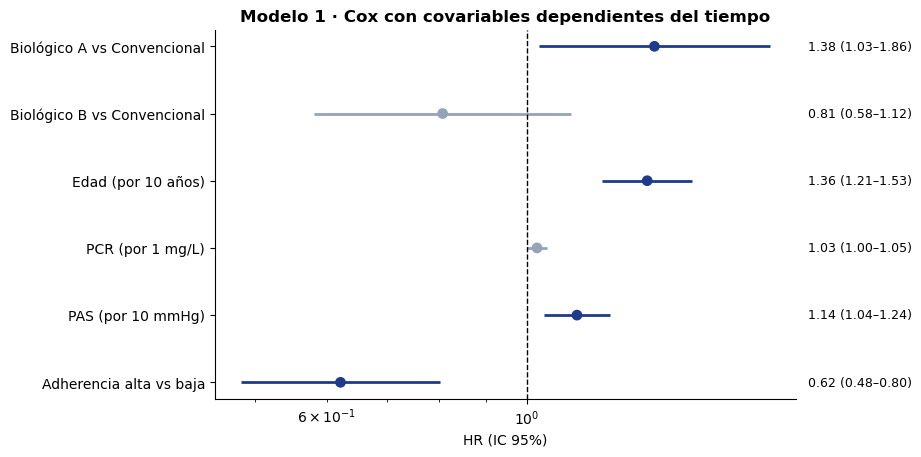

,variable,codigo,coef,ee,z,HR,HR_inf,HR_sup,p
0,Biológico A vs Convencional,trat_A,0.326,0.150,2.170,1.385,1.032,1.858,0.030
1,Biológico B vs Convencional,trat_B,-0.215,0.167,-1.287,0.807,0.582,1.119,0.198
2,Edad (por 10 años),edad10,0.307,0.059,5.207,1.360,1.211,1.526,0.000
3,PCR (por 1 mg/L),pcr,0.026,0.013,1.935,1.026,1.000,1.054,0.053
4,PAS (por 10 mmHg),pas10,0.128,0.043,2.955,1.136,1.044,1.237,0.003
5,Adherencia alta vs baja,adh,-0.475,0.129,-3.680,0.622,0.483,0.801,0.000


In [6]:
def ajustar(d, cols):
    c = CoxTimeVaryingFitter().fit(d[["id", "t_start", "t_stop", "evento"] + cols], id_col="id",
                                   event_col="evento", start_col="t_start", stop_col="t_stop",
                                   show_progress=False)
    return SimpleNamespace(params=c.params_[cols].values, bse=c.standard_errors_[cols].values,
                           cov=c.variance_matrix_.values, llf=c.log_likelihood_,
                           pvalues=c.summary.loc[cols, "p"].values)


def aic(r, k):
    return -2 * r.llf + 2 * k


def tabla_coef(r, cols):
    b, se = r.params, r.bse
    return pd.DataFrame({"variable": [ETQ.get(c, c) for c in cols], "codigo": cols, "coef": b, "ee": se,
                         "z": b / se, "HR": np.exp(b), "HR_inf": np.exp(b - Z * se),
                         "HR_sup": np.exp(b + Z * se), "p": r.pvalues})


def forest(tab, titulo, archivo):
    n = len(tab); y = np.arange(n)[::-1]
    sig = tab["p"].values < .05
    color = np.where(sig, "#1E3A8A", "#94A3B8")
    fig, ax = plt.subplots(figsize=(7.5, .55 * n + 1.5))
    ax.hlines(y, tab.HR_inf, tab.HR_sup, color=color, lw=2)
    ax.scatter(tab.HR, y, color=color, zorder=3, s=45)
    ax.axvline(1, color="k", ls="--", lw=1)
    ax.set(yticks=y, yticklabels=tab.variable, xscale="log", title=titulo, xlabel="HR (IC 95%)")
    for yi, r in zip(y, tab.itertuples()):
        ax.text(1.02, yi, f"{r.HR:.2f} ({r.HR_inf:.2f}–{r.HR_sup:.2f})",
                transform=ax.get_yaxis_transform(), va="center", fontsize=9)
    ax.grid(axis="y", alpha=0)
    guardar_fig(archivo)


r1 = ajustar(df, COV)
tab1 = tabla_coef(r1, COV)
guardar_tab(tab1.assign(p=tab1.p.map(fmt_p)), "02_cox_modelo1.csv")
wald = float(r1.params @ np.linalg.solve(r1.cov, r1.params))
print(f"Wald global = {wald:.2f} (gl = {len(COV)}, p = {fmt_p(stats.chi2.sf(wald, len(COV)))})  |  eventos = {int(df.evento.sum())}")
forest(tab1, "Modelo 1 · Cox con covariables dependientes del tiempo", "fig03_forest_modelo1.png")
tab1.round(3)

## 3. Supuestos del modelo
### 3.1 Riesgos proporcionales (residuos de Schoenfeld, prueba de Grambsch–Therneau)

  g(t)                    variable     rho    chi2      p
log(t) Biológico A vs Convencional  0.4922 28.3348 0.0000
log(t) Biológico B vs Convencional -0.4342 10.4561 0.0012
log(t)          Edad (por 10 años)  0.0544  0.2192 0.6396
log(t)            PCR (por 1 mg/L)  0.0293  0.1291 0.7194
log(t)           PAS (por 10 mmHg) -0.0275  0.0032 0.9547
log(t)     Adherencia alta vs baja  0.0486  0.2092 0.6474
log(t)                      GLOBAL     NaN 79.4740 0.0000


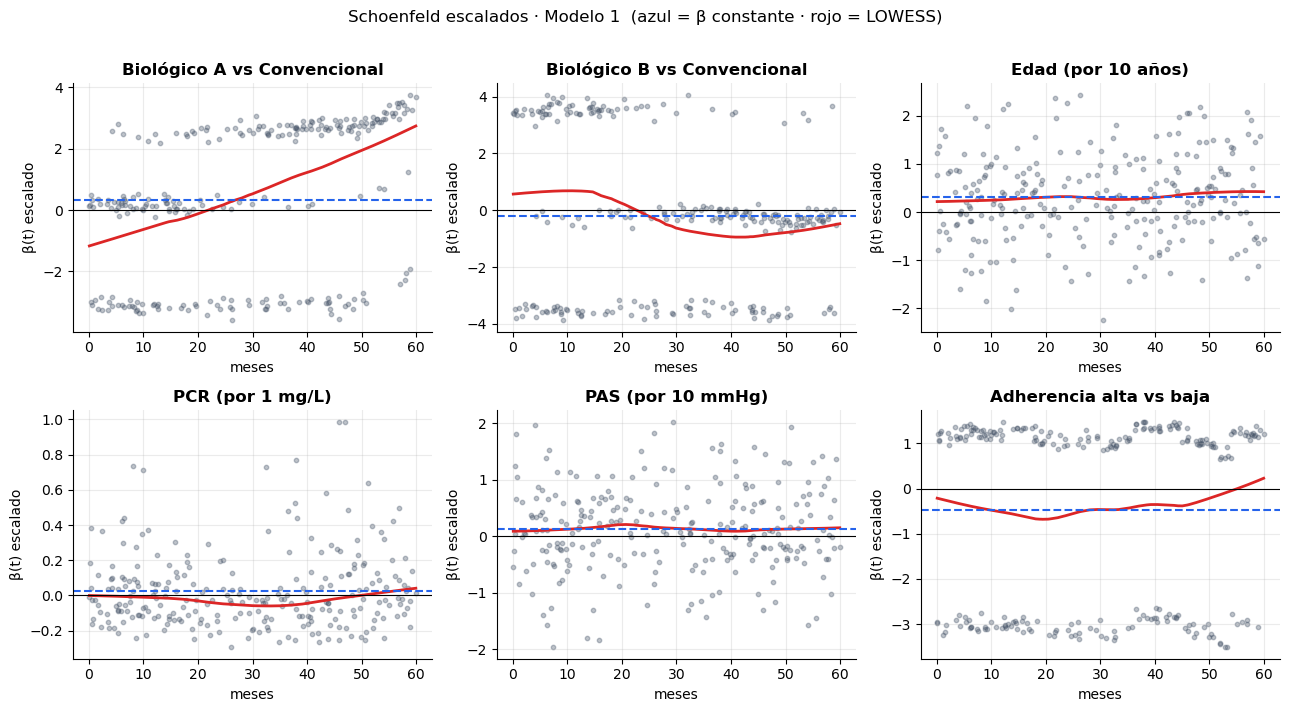

In [7]:
def schoenfeld(r, d, cols):
    """Residuo de Schoenfeld en cada evento: x_i - promedio ponderado (por exp(xb)) del conjunto en riesgo."""
    X, t, t0 = d[cols].values, d["t_stop"].values, d["t_start"].values
    w = np.exp(X @ r.params)
    ev = np.flatnonzero(d["evento"].values == 1)
    res = np.empty((len(ev), len(cols)))
    for k, i in enumerate(ev):
        rs = (t0 < t[i]) & (t >= t[i])
        res[k] = X[i] - (w[rs, None] * X[rs]).sum(0) / w[rs].sum()
    return res, t[ev]


def prueba_ph(r, d, nombres):
    s, t = schoenfeld(r, d, nombres)
    V, nev, filas = r.cov, len(t), []
    for nom_g, gt in (("log(t)", np.log(t)), ("rango de t", stats.rankdata(t))):
        xx = gt - gt.mean(); sxx = (xx ** 2).sum(); u = xx @ s
        z = (nev * (V @ u)) ** 2 / (nev * np.diag(V) * sxx)
        for j, n in enumerate(nombres):
            filas.append((nom_g, ETQ.get(n, n), np.corrcoef(xx, s[:, j])[0, 1], z[j], stats.chi2.sf(z[j], 1)))
        gl = nev * u @ V @ u / sxx
        filas.append((nom_g, "GLOBAL", np.nan, gl, stats.chi2.sf(gl, len(nombres))))
    return pd.DataFrame(filas, columns=["g(t)", "variable", "rho", "chi2", "p"])


def graf_schoenfeld(r, d, nombres, archivo, titulo):
    s, t = schoenfeld(r, d, nombres)
    sc = len(t) * (s @ r.cov) + r.params          # residuos escalados + beta
    fig, axs = plt.subplots(int(np.ceil(len(nombres) / 3)), 3, figsize=(13, 3.5 * np.ceil(len(nombres) / 3)))
    axs = np.atleast_1d(axs).ravel(); web = {}
    for j, n in enumerate(nombres):
        ls = lowess(sc[:, j], t, frac=.5)
        axs[j].scatter(t, sc[:, j], s=10, alpha=.35, color="#475569")
        axs[j].plot(ls[:, 0], ls[:, 1], color="#DC2626", lw=2)
        axs[j].axhline(r.params[j], color="#2563EB", ls="--"); axs[j].axhline(0, color="k", lw=.8)
        axs[j].set(title=ETQ.get(n, n), xlabel="meses", ylabel="β(t) escalado")
        web[n] = {"t": t, "res": sc[:, j], "lx": ls[:, 0], "ly": ls[:, 1], "beta": r.params[j]}
    for a in axs[len(nombres):]: a.axis("off")
    fig.suptitle(titulo + "  (azul = β constante · rojo = LOWESS)", y=1.01)
    fig.tight_layout(); guardar_fig(archivo)
    return web


ph1 = prueba_ph(r1, df, COV)
guardar_tab(ph1.assign(p=ph1.p.map(fmt_p)).round(3), "03_ph_modelo1.csv")
print(ph1[ph1["g(t)"] == "log(t)"].round(4).to_string(index=False))
sch1 = graf_schoenfeld(r1, df, COV, "fig04_schoenfeld_modelo1.png", "Schoenfeld escalados · Modelo 1")

### 3.2 Linealidad de las covariables continuas

Verificación lifelines vs statsmodels: dif. máx. coef. = 3.5e-15


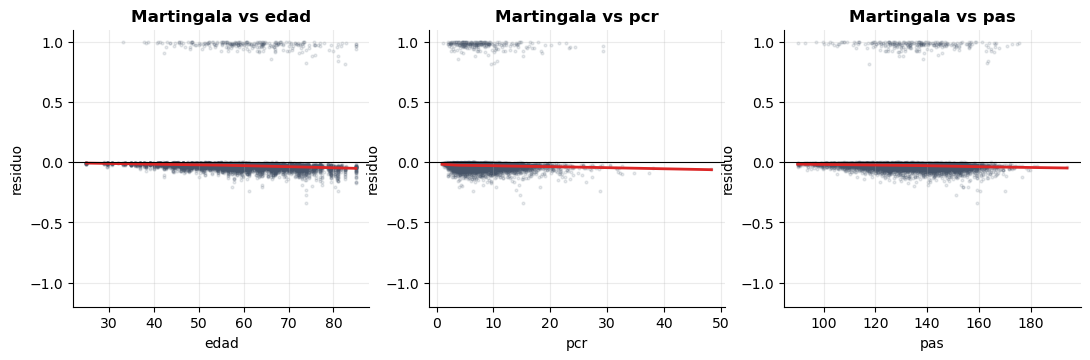

,variable,alternativa,coef,p,delta_AIC
0,Edad (por 10 años),término cuadrático,-0.039,0.379,1.192
1,PCR (por 1 mg/L),término cuadrático,0.000,0.800,1.938
2,PAS (por 10 mmHg),término cuadrático,0.039,0.036,-1.948
3,PCR,log(PCR) en vez de PCR,0.170,0.163,1.548


In [8]:
# Residuos de martingala e influencia: statsmodels (mismo modelo; ver verificación)
m1 = PHReg(df.t_stop.values, df[COV].values, status=df.evento.values, entry=df.t_start.values, ties="efron")
r1p = m1.fit()
print(f"Verificación lifelines vs statsmodels: dif. máx. coef. = {np.abs(r1p.params - r1.params).max():.1e}")
H = r1p.baseline_cumulative_hazard_function[0]
mart = df.evento.values - np.exp(df[COV].values @ r1p.params) * (H(df.t_stop.values) - H(df.t_start.values))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for a, v in zip(axs, ["edad", "pcr", "pas"]):
    ls = lowess(mart, df[v].values, frac=.4)
    a.scatter(df[v], mart, s=4, alpha=.12, color="#475569")
    a.plot(ls[:, 0], ls[:, 1], color="#DC2626", lw=2); a.axhline(0, color="k", lw=.8)
    a.set(title=f"Martingala vs {v}", xlabel=v, ylabel="residuo", ylim=(-1.2, 1.1))
guardar_fig("fig05_linealidad.png")

filas, aic0 = [], aic(r1, len(COV))
for v in ["edad10", "pcr", "pas10"]:
    d2 = df.assign(cuad=(df[v] - df[v].mean()) ** 2)
    r2c = ajustar(d2, COV + ["cuad"])
    filas.append((ETQ[v], "término cuadrático", r2c.params[-1], r2c.pvalues[-1], aic(r2c, len(COV) + 1) - aic0))
r3c = ajustar(df.assign(log_pcr=np.log(df.pcr)), [c for c in COV if c != "pcr"] + ["log_pcr"])
filas.append(("PCR", "log(PCR) en vez de PCR", r3c.params[-1], r3c.pvalues[-1], aic(r3c, len(COV)) - aic0))
lin = pd.DataFrame(filas, columns=["variable", "alternativa", "coef", "p", "delta_AIC"])
guardar_tab(lin.assign(p=lin.p.map(fmt_p)).round(3), "04_linealidad.csv")
lin.round(3)

### 3.3 Observaciones influyentes (dfbeta por paciente)

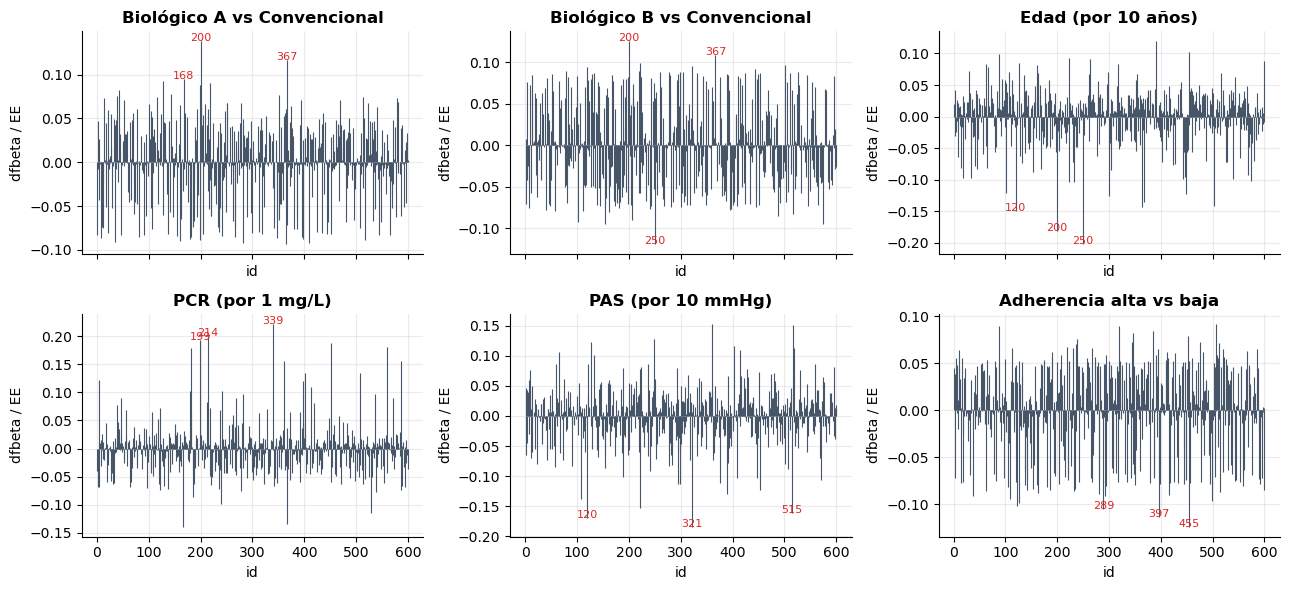

,id,max |dfbeta/EE|,coeficiente
0,339,0.222,PCR (por 1 mg/L)
1,250,0.202,Edad (por 10 años)
2,214,0.200,PCR (por 1 mg/L)
3,199,0.194,PCR (por 1 mg/L)
4,452,0.189,PCR (por 1 mg/L)
5,321,0.184,PAS (por 10 mmHg)
6,560,0.182,PCR (por 1 mg/L)
7,200,0.181,Edad (por 10 años)
8,181,0.179,PCR (por 1 mg/L)
9,120,0.170,PAS (por 10 mmHg)


In [9]:
dfb = pd.DataFrame(m1.score_residuals(r1p.params) @ r1p.cov_params(), columns=COV)
dfb["id"] = df["id"].values
dfbs = dfb.groupby("id").sum() / r1p.bse
fig, axs = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for a, c in zip(axs.ravel(), COV):
    a.vlines(dfbs.index, 0, dfbs[c], color="#475569", lw=.8)
    for i in dfbs[c].abs().nlargest(3).index:
        a.annotate(str(i), (i, dfbs.loc[i, c]), fontsize=8, color="#DC2626", ha="center")
    a.set(title=ETQ[c], xlabel="id", ylabel="dfbeta / EE")
fig.tight_layout(); guardar_fig("fig06_influencia.png")
top = dfbs.abs().max(axis=1).nlargest(10)
infl = pd.DataFrame({"id": top.index, "max |dfbeta/EE|": top.values,
                     "coeficiente": [ETQ[dfbs.loc[i].abs().idxmax()] for i in top.index]})
guardar_tab(infl.round(3), "05_influyentes.csv")
infl.round(3)

## 4. Medidas correctivas
Si el tratamiento viola riesgos proporcionales, se modela su efecto **dependiente del tiempo**:
`tratamiento × log(t)`. Para ello se divide cada intervalo en los tiempos de evento.

In [10]:
def dividir(d, cortes):
    cortes = np.unique(np.asarray(cortes, float))
    st, sp = d.t_start.values, d.t_stop.values
    lo, hi = np.searchsorted(cortes, st, "right"), np.searchsorted(cortes, sp, "left")
    idx = np.repeat(np.arange(len(d)), hi - lo + 1)
    ini, fin = [], []
    for i in range(len(d)):
        b = np.concatenate(([st[i]], cortes[lo[i]:hi[i]], [sp[i]]))
        ini.extend(b[:-1]); fin.extend(b[1:])
    out = d.iloc[idx].reset_index(drop=True)
    ultimo = np.r_[idx[1:] != idx[:-1], True]
    out["t_start"], out["t_stop"] = ini, fin
    out["evento"] = np.where(ultimo, out.evento.values, 0)
    return out


s = dividir(df, df.loc[df.evento == 1, "t_stop"].unique())
s["A_lt"], s["B_lt"] = s.trat_A * np.log(s.t_stop), s.trat_B * np.log(s.t_stop)
r1s = ajustar(s, COV)                       # control: debe reproducir el modelo 1
print(f"Filas: {len(df)} -> {len(s)} | control (dif. máx. coef.) = {np.abs(r1s.params - r1.params).max():.1e}")

COV2 = COV + ["A_lt", "B_lt"]
r2 = ajustar(s, COV2)
tab2 = tabla_coef(r2, COV2)
guardar_tab(tab2.assign(p=tab2.p.map(fmt_p)), "06_cox_modelo2.csv")
lrt = 2 * (r2.llf - r1.llf)
print(f"LRT modelo 2 vs 1: chi2 = {lrt:.2f}, gl = 2, p = {fmt_p(stats.chi2.sf(lrt, 2))} | "
      f"AIC: {aic(r1, 6):.1f} -> {aic(r2, 8):.1f}")
tab2.round(3)

Filas: 7636 -> 103411 | control (dif. máx. coef.) = 4.3e-15
LRT modelo 2 vs 1: chi2 = 113.10, gl = 2, p = <0.001 | AIC: 2929.5 -> 2820.4


,variable,codigo,coef,ee,z,HR,HR_inf,HR_sup,p
0,Biológico A vs Convencional,trat_A,-5.884,0.964,-6.106,0.003,0.000,0.018,0.000
1,Biológico B vs Convencional,trat_B,0.835,0.434,1.923,2.305,0.984,5.398,0.055
2,Edad (por 10 años),edad10,0.309,0.059,5.207,1.363,1.213,1.531,0.000
3,PCR (por 1 mg/L),pcr,0.019,0.014,1.414,1.019,0.993,1.047,0.157
4,PAS (por 10 mmHg),pas10,0.131,0.042,3.094,1.141,1.049,1.240,0.002
5,Adherencia alta vs baja,adh,-0.557,0.130,-4.289,0.573,0.444,0.739,0.000
6,Biológico A × log(t),A_lt,1.880,0.278,6.762,6.550,3.799,11.294,0.000
7,Biológico B × log(t),B_lt,-0.409,0.153,-2.676,0.664,0.492,0.896,0.007


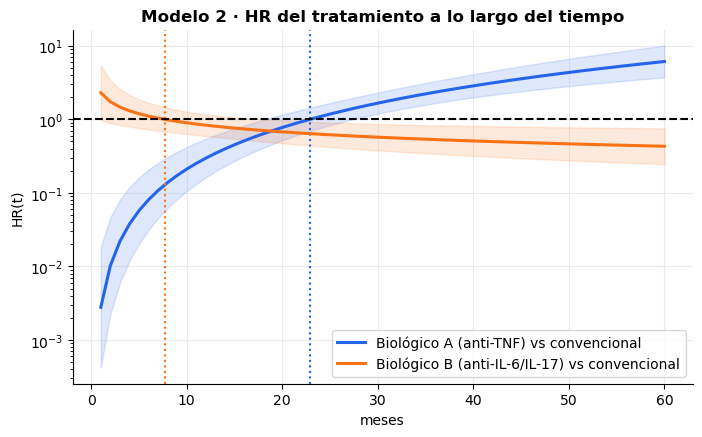

HR = 1 en t ≈ 22.9 m (A) y 7.7 m (B)


,tratamiento,t (meses),HR,HR_inf,HR_sup
0,Biológico A (anti-TNF),3,0.02,0.01,0.08
1,Biológico A (anti-TNF),6,0.08,0.03,0.21
2,Biológico A (anti-TNF),12,0.30,0.16,0.54
3,Biológico A (anti-TNF),24,1.09,0.77,1.56
4,Biológico A (anti-TNF),36,2.34,1.66,3.30
5,Biológico A (anti-TNF),48,4.02,2.66,6.09
6,Biológico A (anti-TNF),60,6.12,3.72,10.06
7,Biológico B (anti-IL-6/IL-17),3,1.47,0.84,2.58
8,Biológico B (anti-IL-6/IL-17),6,1.11,0.73,1.68
9,Biológico B (anti-IL-6/IL-17),12,0.83,0.59,1.17


In [11]:
def hr_t(r, base, inter, t):
    ib, ii = COV2.index(base), COV2.index(inter)
    V, b, g_ = r.cov, r.params, np.log(np.asarray(t, float))
    se = np.sqrt(V[ib, ib] + g_ ** 2 * V[ii, ii] + 2 * g_ * V[ib, ii])
    lp = b[ib] + b[ii] * g_
    return np.exp(lp), np.exp(lp - Z * se), np.exp(lp + Z * se)


tg = np.arange(1, 61.0)
curvas, cruces, filas = {}, {}, []
fig, ax = plt.subplots(figsize=(8, 4.6))
for base, inter, tid in (("trat_A", "A_lt", "Biologico_A"), ("trat_B", "B_lt", "Biologico_B")):
    h, lo, hi = hr_t(r2, base, inter, tg)
    curvas[base] = {"t": tg, "hr": h, "lo": lo, "hi": hi}
    cruces[base] = float(np.exp(-r2.params[COV2.index(base)] / r2.params[COV2.index(inter)]))
    ax.plot(tg, h, color=COL[tid], lw=2.2, label=ETQ_T[tid] + " vs convencional")
    ax.fill_between(tg, lo, hi, color=COL[tid], alpha=.15)
    ax.axvline(cruces[base], color=COL[tid], ls=":")
    for tt in (3, 6, 12, 24, 36, 48, 60):
        a_, b_, c_ = hr_t(r2, base, inter, [tt]); filas.append((ETQ_T[tid], tt, a_[0], b_[0], c_[0]))
ax.axhline(1, color="k", ls="--")
ax.set(yscale="log", xlabel="meses", ylabel="HR(t)", title="Modelo 2 · HR del tratamiento a lo largo del tiempo")
ax.legend(); guardar_fig("fig07_hr_tiempo.png")
hr_tab = pd.DataFrame(filas, columns=["tratamiento", "t (meses)", "HR", "HR_inf", "HR_sup"])
guardar_tab(hr_tab.round(3), "07_hr_en_el_tiempo.csv")
print(f"HR = 1 en t ≈ {cruces['trat_A']:.1f} m (A) y {cruces['trat_B']:.1f} m (B)")
hr_tab.round(2)

  g(t)                    variable     rho    chi2      p
log(t) Biológico A vs Convencional  0.0000  1.1190 0.2901
log(t) Biológico B vs Convencional -0.0000  6.8297 0.0090
log(t)          Edad (por 10 años)  0.0324  0.2657 0.6062
log(t)            PCR (por 1 mg/L)  0.0127  0.0253 0.8737
log(t)           PAS (por 10 mmHg) -0.0013  0.0006 0.9802
log(t)     Adherencia alta vs baja  0.0314  0.1881 0.6645
log(t)        Biológico A × log(t)  0.0160  0.8481 0.3571
log(t)        Biológico B × log(t) -0.0763  8.3232 0.0039
log(t)                      GLOBAL     NaN 11.2802 0.1863


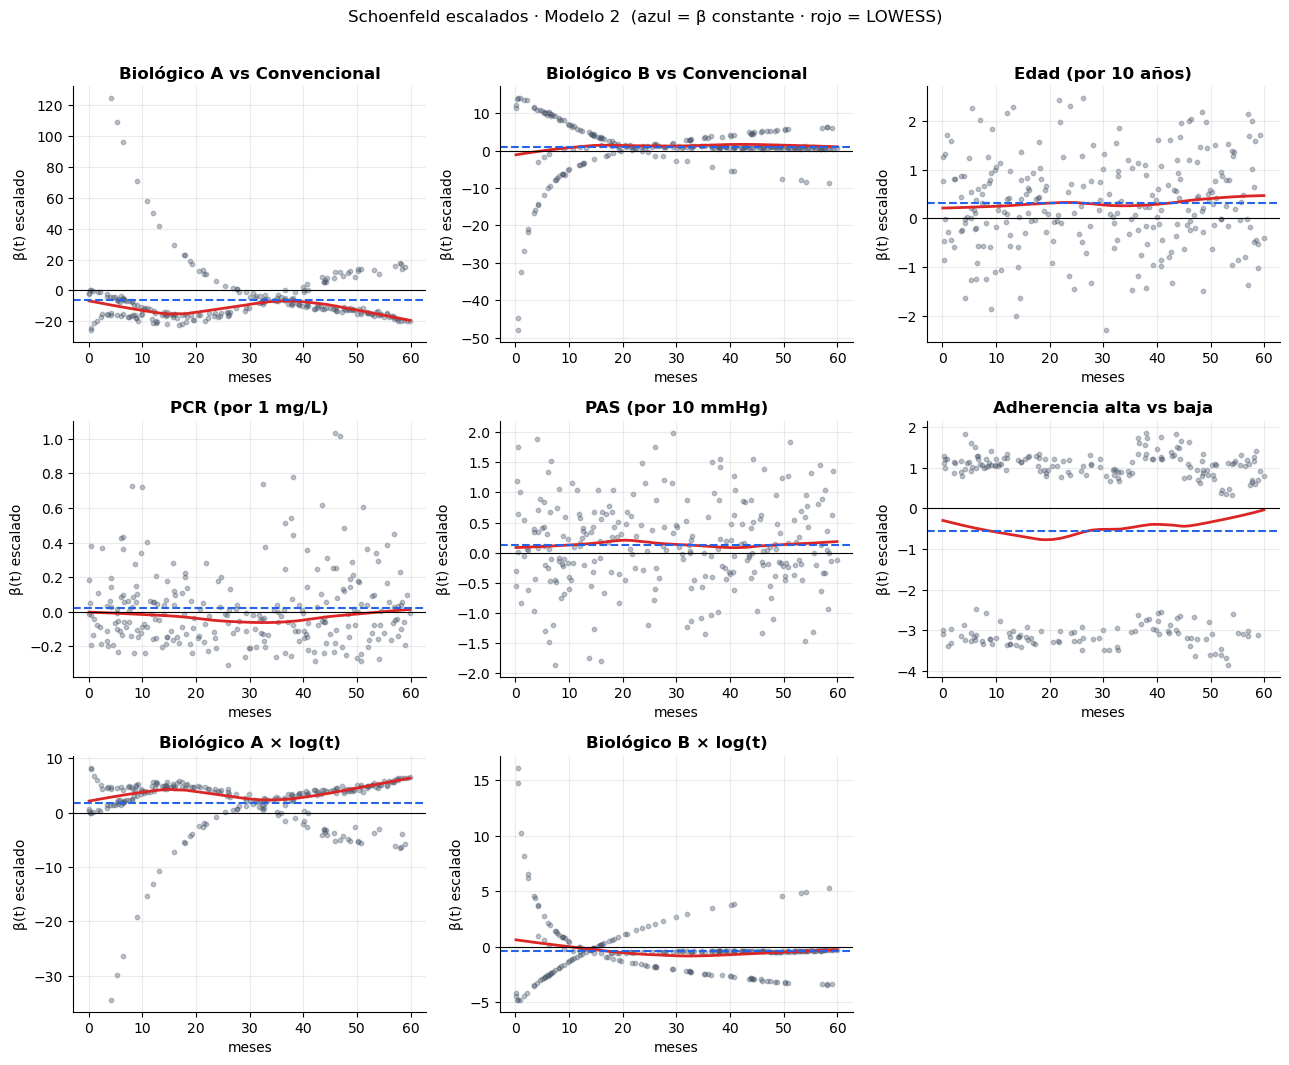

In [12]:
# Reevaluación de supuestos del modelo corregido
ph2 = prueba_ph(r2, s, COV2)
guardar_tab(ph2.assign(p=ph2.p.map(fmt_p)).round(3), "08_ph_modelo2.csv")
print(ph2[ph2["g(t)"] == "log(t)"].round(4).to_string(index=False))
sch2 = graf_schoenfeld(r2, s, COV2, "fig08_schoenfeld_modelo2.png", "Schoenfeld escalados · Modelo 2")

## 5. Exportar para la página web

In [13]:
def limpiar(o):
    if isinstance(o, dict): return {str(k): limpiar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpiar(v) for v in o]
    if isinstance(o, pd.DataFrame): return limpiar(o.to_dict("records"))
    if isinstance(o, np.ndarray): return limpiar(o.tolist())
    if isinstance(o, (np.integer, int)): return int(o)
    if isinstance(o, (np.floating, float)): return round(float(o), 5) if np.isfinite(o) else None
    return o


R = {"etiquetas": {"trat": ETQ_T, "cov": ETQ, "colores": COL},
     "tabla1": tabla1.reset_index(), "km": km_web, "logrank_p": lr.p_value,
     "trayectorias": tr.assign(tratamiento=tr.tratamiento.astype(str)),
     "cox1": tab1, "ph1": ph1, "schoenfeld1": sch1, "linealidad": lin, "influyentes": infl,
     "cox2": tab2, "hr_curvas": curvas, "hr_tabla": hr_tab, "cruces": cruces, "ph2": ph2, "schoenfeld2": sch2}
(WEB_DATA / "resultados.js").write_text("const RESULTADOS = " + json.dumps(limpiar(R), ensure_ascii=False) + ";\n", encoding="utf-8")

pacientes = {int(i): {"trat": str(gr.tratamiento.iloc[0]), "edad": float(gr.edad.iloc[0]),
                      "filas": gr[["t_start", "t_stop", "evento", "pcr", "pas", "adh"]].values.tolist()}
             for i, gr in df.groupby("id")}
(WEB_DATA / "pacientes.js").write_text("const PACIENTES = " + json.dumps(limpiar(pacientes), separators=(",", ":")) + ";\n", encoding="utf-8")
for f in FIG.glob("*.png"): shutil.copy(f, WEB_IMG / f.name)
for f in TAB.glob("*.csv"): shutil.copy(f, WEB_DATA / f.name)
print("Listo: salida/tablas, salida/figuras, web/data (resultados.js, pacientes.js, CSV), web/imagenes")

Listo: salida/tablas, salida/figuras, web/data (resultados.js, pacientes.js, CSV), web/imagenes
